<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/3_Analisis_y_visualizacion_datos/7_Dataton.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏦 **DATATÓN: El Misterio de la Fuga de Clientes**
## **Misión de consultoría para la Junta Directiva del Banco Externado**
---

## 📄 Contexto del negocio

**Cliente:** Junta Directiva del Banco Externado

**Su rol:** Equipo de Analistas de Datos (*Data Scientists*)

**Tiempo límite:** hasta el final de la clase

El Banco Externado se enfrenta a una crisis sin precedentes. En el último trimestre, la tasa de abandono de clientes (**fuga**) se disparó. Cada cliente que cierra sus cuentas representa una pérdida enorme en valor presente neto para la entidad. La Junta Directiva necesita entender **quiénes se están yendo y por qué**, para diseñar una política de retención urgente.

El departamento de Ingeniería de Sistemas logró extraer la información de los clientes, pero —como suele ocurrir en la vida real— **los datos son un desastre**: vienen en dos archivos separados, con valores nulos, formatos extraños, registros repetidos y errores de digitación.

**Su misión:** limpiar, integrar, transformar y explorar estos datos para presentar un diagnóstico económico a la Junta Directiva antes de que cierre la bolsa.

## 💾 Diccionario de datos

**1. `banco_clientes.csv` — Información demográfica**

| Columna | Descripción |
|---|---|
| `ID_Cliente` | Identificador único del usuario. |
| `Edad` | Edad del cliente en años. |
| `Ingreso_Mensual` | Ingresos mensuales estimados en pesos. |
| `Genero` | Género del cliente (digitado a mano por el asesor). |
| `Ciudad` | Ciudad de residencia (digitada a mano por el asesor). |
| `Fecha_Ingreso` | Fecha de vinculación al banco, **guardada como texto** en formato `DD/MM/AAAA`. |

**2. `banco_transacciones.csv` — Información de comportamiento**

| Columna | Descripción |
|---|---|
| `ID_Cliente` | Identificador único del usuario. **Ojo:** el core bancario exporta parte de los IDs con el prefijo del sistema (`CLI-00145`). |
| `Saldo_Cuenta` | Dinero promedio en la cuenta. |
| `Cant_Productos` | Número de productos activos (tarjetas, créditos, CDT, etc.). |
| `Fuga_Ultimo_Mes` | **Variable objetivo.** `1` si el cliente abandonó el banco, `0` si continúa activo. |

## 📋 Instrucciones generales

- Trabajen en **equipos de 2 personas**, en este mismo notebook.
- Completen el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Pueden añadir todas las celdas que necesiten.
- **No modifiquen** la celda de verificación (la última celda de código del notebook).
- Usen **exactamente** los nombres de variables que pide cada enunciado: la verificación automática los busca por nombre.
- Los retos son **acumulativos**: el reto 4 usa el resultado del reto 2. Si un punto sale ❌, revísenlo antes de seguir, porque arrastra a los siguientes.
- Al final, ejecuten la **celda de verificación**: les dirá qué porcentaje llevan y en cuál punto exacto se equivocaron. Pueden ejecutarla todas las veces que quieran mientras trabajan.
- Los puntos de **análisis escrito** no dan puntaje automático: los revisará posteriormente la profesora.

### ✅ Checklist de nombres exactos

La verificación busca estas variables. Consérvenlas escritas tal cual:

| Reto | Variables |
|---|---|
| 1 | `RUTA_DATOS`, `df_clientes`, `df_transacciones`, `n_duplicados`, `df_banco`, `dim_banco` |
| 2 | `mediana_edad`, `mediana_ingreso`, `generos_finales`, `ciudades_finales`, `nulos_restantes`, `edad_maxima` |
| 3 | `q1_saldo`, `q3_saldo`, `iqr_saldo`, `limite_inferior_saldo`, `limite_superior_saldo`, `n_outliers_saldo`, `decision_outliers` |
| 4 | `Ingreso_Anual`, `Antiguedad_Anios`, `Ratio_Ahorro` (columnas), `ratio_por_fuga`, `resumen_saldo` |
| 5 | `Segmento_Ingreso` (columna), `conteo_segmentos`, `fuga_por_segmento` |
| 6 | `tasa_fuga_productos`, `ingreso_por_fuga`, `tabla_ejecutiva`, `matriz_correlacion`, `correlacion_con_fuga` |
| 7 | `pitch_economico`, `recomendaciones` |
| 8 | `df_ml` |

---
## ⚙️ Preparación del entorno

Ejecuta las dos celdas siguientes **sin modificarlas**.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Que muestre todas las columnas
pd.options.display.max_columns = None
# En los dataframes, mostrar los float con dos decimales
pd.options.display.float_format = '{:,.2f}'.format

### 📂 Antes de empezar: llevar los datos a Colab

Colab arranca con una máquina vacía, así que los dos archivos (`banco_clientes.csv` y `banco_transacciones.csv`) tienen que quedar al alcance del notebook. Hay dos formas; **elijan la que prefieran**:

| Cómo | Qué hacer | Ojo |
|---|---|---|
| **Panel de archivos** | Abrir el ícono de carpeta 📁 de la barra izquierda y arrastrar los dos CSV. | Es la más rápida, pero **los archivos se pierden** si el entorno se reinicia y toca volver a subirlos. |
| **Google Drive** | Guardar los CSV en una carpeta de su Drive y ejecutar `from google.colab import drive` y `drive.mount('/content/drive')`. | Los archivos no se pierden si el entorno se reinicia. |

---
# 🔍 **Reto 1: Auditoría e Integración de la Información**

Antes de analizar nada hay que saber **qué tan sucios están los datos** y unir las dos bases.

**1.1 Carga y auditoría.** Importa los dos archivos en `df_clientes` y `df_transacciones` y revísalos con `.info()`. Fíjate en el tipo de dato de cada columna: hay al menos uno que no es el que debería ser.

In [14]:
df_clientes = pd.read_csv('banco_clientes.csv')
df_transacciones = pd.read_csv('banco_transacciones.csv')

print("\n--- Info for df_clientes ---")
df_clientes.info()

print("\n--- Info for df_transacciones ---")
df_transacciones.info()


--- Info for df_clientes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3060 entries, 0 to 3059
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID_Cliente       3060 non-null   int64  
 1   Edad             3009 non-null   float64
 2   Ingreso_Mensual  2957 non-null   float64
 3   Genero           3060 non-null   object 
 4   Ciudad           3060 non-null   object 
 5   Fecha_Ingreso    3060 non-null   object 
dtypes: float64(2), int64(1), object(3)
memory usage: 143.6+ KB

--- Info for df_transacciones ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2550 entries, 0 to 2549
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID_Cliente       2550 non-null   object 
 1   Saldo_Cuenta     2550 non-null   float64
 2   Cant_Productos   2550 non-null   int64  
 3   Fuga_Ultimo_Mes  2550 non-null   int64  
dtypes: float64

**1.2 Registros repetidos.** La extracción del sistema se corrió dos veces y algunos clientes quedaron duplicados.

1. Cuenta cuántas **filas completamente duplicadas** hay en `df_clientes` y guarda ese número (como entero) en `n_duplicados`.
2. Elimina los duplicados de `df_clientes`, conservando la primera aparición de cada cliente.

In [15]:
n_duplicados = df_clientes.duplicated().sum()
df_clientes = df_clientes.drop_duplicates(keep='first')

**1.3 La llave no coincide.** Si intentas unir las dos tablas ahora mismo, pandas te lanzará un error parecido a este:

```
ValueError: You are trying to merge on int64 and object columns for key 'ID_Cliente'
```

Eso ocurre porque en `df_transacciones` el `ID_Cliente` llega como **texto** (parte de los registros traen el prefijo `CLI-`), mientras que en `df_clientes` es un número. No se puede cruzar una tabla por una llave de tipo texto con otra de tipo número.

Deja el `ID_Cliente` de `df_transacciones` como número entero, quitándole el prefijo `CLI-` y los ceros de relleno.

> 💡 `.astype(str)` → `.str.replace('CLI-', '', regex=False)` → `.astype(int)`

In [16]:
df_transacciones['ID_Cliente'] = df_transacciones['ID_Cliente'].astype(str).str.replace('CLI-', '', regex=False).astype(int)

**1.4 La unión.** Une las dos tablas usando `ID_Cliente` como llave y guarda el resultado en `df_banco`.

**No pueden perderse** los clientes que están en la base demográfica pero no tienen transacciones recientes: ese grupo es justamente el más sospechoso de haberse fugado. *(Pista: piensa qué tipo de `merge` conserva todas las filas de la tabla izquierda.)*

Luego:
- Guarda las dimensiones del resultado en `dim_banco` (usa `df_banco.shape`).
- Imprime esas dimensiones y muestra las 3 primeras filas.

In [17]:
df_banco = pd.merge(df_clientes, df_transacciones, on='ID_Cliente', how='left')
dim_banco = df_banco.shape
print(f"Dimensiones de df_banco: {dim_banco}")
display(df_banco.head(3))

Dimensiones de df_banco: (3000, 9)


,ID_Cliente,Edad,Ingreso_Mensual,Genero,Ciudad,Fecha_Ingreso,Saldo_Cuenta,Cant_Productos,Fuga_Ultimo_Mes
0,1,41.50,"5,409,375.42",Otro,Medellín,22/05/2022,"2,631.12",4.00,0.00
1,2,42.20,"5,794,482.72",F,Medellín,28/09/2020,"57,593.85",4.00,0.00
2,3,46.95,"3,457,252.49",Otro,bogota,21/05/2021,"4,791.41",4.00,0.00


---
# 🧹 **Reto 2: Limpieza**

Los modelos de *Machine Learning* odian la basura. Hay que dejar la base impecable.

**2.1 Estandarizar `Genero`.** La columna fue llenada a mano y tiene inconsistencias (`M`, `m`, `F`, `f`, `Otro`). Unifícala para que existan **exactamente** estas 3 categorías, escritas así:

`Femenino`, `Masculino`, `Otro`

Después, guarda en `generos_finales` la lista **ordenada alfabéticamente** de las categorías que quedaron. *(Pista: `sorted(...)` sobre los valores únicos.)*

In [18]:
df_banco['Genero'] = df_banco['Genero'].str.upper().replace({'F': 'Femenino', 'M': 'Masculino', 'OTRO': 'Otro'})
generos_finales = sorted(df_banco['Genero'].unique().tolist())

**2.2 Estandarizar `Ciudad`.** Mismo problema, pero peor: hay espacios sobrantes, mayúsculas y tildes faltantes (`' Bogotá '`, `'bogota'`, `'BOGOTA'`...). Unifícala para que existan **exactamente** estas 4 categorías, escritas así:

`Barranquilla`, `Bogotá`, `Cali`, `Medellín`

Guarda en `ciudades_finales` la lista ordenada alfabéticamente de las categorías que quedaron.

> 💡 Encadena `.str.strip()` (quita espacios), `.str.title()` (deja solo la primera letra en mayúscula) y un `.replace({...})` para las versiones sin tilde.

In [20]:
df_banco['Ciudad'] = df_banco['Ciudad'].astype(str).str.strip().str.title().replace(
    {'Bogota': 'Bogotá', 'Cali ': 'Cali', 'Medellin': 'Medellín'}
)
ciudades_finales = sorted(df_banco['Ciudad'].unique().tolist())

**2.3 Valores nulos.** Revisa cuántos nulos hay por columna con `.isna().sum()` y luego impútalos **en este orden y con estos criterios**:

| Columna | Imputar con | Por qué |
|---|---|---|
| `Edad` | la **mediana** (guárdala en `mediana_edad`) |  |
| `Ingreso_Mensual` | la **mediana** (guárdala en `mediana_ingreso`) |  |
| `Saldo_Cuenta` | `0` | Si no aparece en la base transaccional, el cliente no tiene saldo con el banco. |
| `Cant_Productos` | `0` | Mismo razonamiento: no tiene productos activos. |
| `Fuga_Ultimo_Mes` | `1` |  |

Al terminar, guarda en `nulos_restantes` el total de nulos que quedan en toda la base (debe ser `0`).

> ⚠️ Calcula las dos medianas **antes** de imputar y guárdalas en `mediana_edad` y `mediana_ingreso`: las vas a volver a usar en el punto 2.4.

In [24]:
print(df_banco.isna().sum())

ID_Cliente         0
Edad               0
Ingreso_Mensual    0
Genero             0
Ciudad             0
Fecha_Ingreso      0
Saldo_Cuenta       0
Cant_Productos     0
Fuga_Ultimo_Mes    0
dtype: int64


In [25]:
mediana_edad = df_banco['Edad'].median()
mediana_ingreso = df_banco['Ingreso_Mensual'].median()

df_banco['Edad'] = df_banco['Edad'].fillna(mediana_edad)
df_banco['Ingreso_Mensual'] = df_banco['Ingreso_Mensual'].fillna(mediana_ingreso)
df_banco['Saldo_Cuenta'] = df_banco['Saldo_Cuenta'].fillna(0)
df_banco['Cant_Productos'] = df_banco['Cant_Productos'].fillna(0)
df_banco['Fuga_Ultimo_Mes'] = df_banco['Fuga_Ultimo_Mes'].fillna(1)

nulos_restantes = df_banco.isna().sum().sum()

**2.4 El cliente de 150 años.** Hay un cliente con una edad imposible. Encuéntralo, y reemplaza por `mediana_edad` la edad de **todo cliente que tenga más de 100 años**.

Guarda en `edad_maxima` la edad máxima que queda en la base después de la corrección.

> 💡 Usa `.loc[condición, 'Edad'] = valor` para modificar solo las filas que cumplen la condición.

In [26]:
df_banco.loc[df_banco['Edad'] > 100, 'Edad'] = mediana_edad
edad_maxima = df_banco['Edad'].max()

📝 **Para la Junta (revisión de la profesora).** En la celda de texto siguiente, justifiquen en 3 o 4 líneas: ¿por qué la **mediana** y no la media para `Edad` e `Ingreso_Mensual`? ¿Qué habría pasado con el promedio de edad si hubieran dejado al cliente de 150 años? ¿Qué supuesto económico están haciendo al imputar `Fuga_Ultimo_Mes = 1`?

✍️ **Escriban aquí su justificación:**

Se usó la mediana en lugar de la media para la 'Edad' e 'Ingreso_Mensual' porque la mediana es menos sensible a valores atípicos. Si hubiéramos dejado el cliente de 150 años, el promedio de edad se habría inflado artificialmente, distorsionando la verdadera distribución de la edad de los clientes. Al imputar `Fuga_Ultimo_Mes = 1` para los clientes sin transacciones recientes, se está asumiendo que estos clientes, al no mostrar actividad, han abandonado el banco o están en proceso de hacerlo, lo que implica una fuga por inactividad.

---
# 📏 **Reto 3: Outliers con criterio estadístico (regla del IQR)**

El cliente de 150 años era un error evidente. Pero en `Saldo_Cuenta` hay valores altísimos que **no** son errores: son clientes con mucho dinero. La pregunta económica es si deben tratarse como datos válidos o como anomalías.

Para decidirlo con un criterio y no "a ojo", se usa la **regla del rango intercuartílico (IQR)**: se considera atípico todo dato que esté por fuera del intervalo

$$[\;Q_1 - 1.5 \cdot IQR\;,\;\; Q_3 + 1.5 \cdot IQR\;]$$

Calcula sobre `Saldo_Cuenta` (ya limpia e imputada) y guarda en estas variables:

- `q1_saldo`: percentil 25 *(pista: `.quantile(0.25)`)*
- `q3_saldo`: percentil 75
- `iqr_saldo`: la diferencia entre ambos
- `limite_inferior_saldo` y `limite_superior_saldo`: los dos extremos de la fórmula
- `n_outliers_saldo`: cuántos clientes (entero) quedan **por fuera** de ese intervalo

Imprime los cinco valores.

In [30]:
q1_saldo = df_banco['Saldo_Cuenta'].quantile(0.25)
q3_saldo = df_banco['Saldo_Cuenta'].quantile(0.75)
iqr_saldo = q3_saldo - q1_saldo
limite_inferior_saldo = q1_saldo - 1.5 * iqr_saldo
limite_superior_saldo = q3_saldo + 1.5 * iqr_saldo
n_outliers_saldo = df_banco[(df_banco['Saldo_Cuenta'] < limite_inferior_saldo) | (df_banco['Saldo_Cuenta'] > limite_superior_saldo)].shape[0]

print(f"Q1 Saldo: {q1_saldo:,.2f}")
print(f"Q3 Saldo: {q3_saldo:,.2f}")
print(f"IQR Saldo: {iqr_saldo:,.2f}")
print(f"Límite Inferior Saldo: {limite_inferior_saldo:,.2f}")
print(f"Límite Superior Saldo: {limite_superior_saldo:,.2f}")
print(f"Número de Outliers de Saldo: {n_outliers_saldo}")

Q1 Saldo: 477.75
Q3 Saldo: 6,867.17
IQR Saldo: 6,389.42
Límite Inferior Saldo: -9,106.39
Límite Superior Saldo: 16,451.31
Número de Outliers de Saldo: 226


**3.2 La decisión.** A diferencia del cliente de 150 años, **estos saldos no se van a corregir**: un saldo de 60 millones es perfectamente posible y, de hecho, corresponde a los clientes más valiosos del banco. Recortarlos borraría justo al segmento que la Junta quiere retener.

Guarda esa decisión argumentada en una variable de texto llamada `decision_outliers` (mínimo 150 caracteres). Explica: ¿por qué un outlier *estadístico* no es lo mismo que un *error de digitación*? ¿Qué se perdería si los elimináramos?

```python
decision_outliers = """Escriban aquí su argumento..."""
```

In [33]:
decision_outliers = """Los outliers estadísticos en 'Saldo_Cuenta' no son errores de digitación como el de la edad, sino representaciones de clientes con saldos elevados, que son valiosos para el banco. Eliminar estos registros borraría información crucial sobre los clientes más rentables, sesgando el análisis y las futuras políticas de retención. No se corrigen porque son datos válidos, aunque atípicos, que ofrecen una visión importante de la distribución real de los saldos."""

print(f"Longitud del argumento: {len(decision_outliers)} caracteres")

Longitud del argumento: 457 caracteres


---
# ⚙️ **Reto 4: Transformación y creación de variables**

**4.1 Ingreso anual.** Crea la columna `Ingreso_Anual` asumiendo 12 meses.

In [34]:
df_banco['Ingreso_Anual'] = df_banco['Ingreso_Mensual'] * 12

**4.2 Antigüedad del cliente.** La columna `Fecha_Ingreso` llegó como texto, así que hoy no sirve para calcular nada.

1. Conviértela a fecha real con `pd.to_datetime(..., format='%d/%m/%Y')`.
2. Crea la columna `Antiguedad_Anios` con los años que lleva cada cliente en el banco **a la fecha de corte del informe**, que es el **1 de enero de 2026** (ya está definida abajo como `FECHA_CORTE`).
3. **Redondea la columna a 2 decimales.**

> 💡 Al restar dos fechas obtienes un `Timedelta`; `.dt.days` te da los días, y se divide entre `365.25` para pasar a años.
>
> ⚠️ Usa `FECHA_CORTE`, **no** la fecha de hoy: así el resultado es el mismo para todos los equipos.

In [35]:
FECHA_CORTE = pd.Timestamp('2026-01-01')   # No modificar

In [36]:
df_banco['Fecha_Ingreso'] = pd.to_datetime(df_banco['Fecha_Ingreso'], format='%d/%m/%Y')
df_banco['Antiguedad_Anios'] = ((FECHA_CORTE - df_banco['Fecha_Ingreso']).dt.days / 365.25).round(2)

**4.3 Un indicador propio: capacidad de ahorro.** El saldo en pesos no dice lo mismo para alguien que gana 1 millón que para alguien que gana 10. Lo informativo es el saldo **relativo al ingreso**.

1. Crea la columna `Ratio_Ahorro` = `Saldo_Cuenta` / `Ingreso_Mensual`.
2. Calcula el promedio de ese ratio para los que se fugaron y para los que se quedaron, y guárdalo en `ratio_por_fuga` *(pista: `groupby` sobre `Fuga_Ultimo_Mes` + `.mean()`)*.
3. Imprime el resultado y obsérvalo: ese número es una de las piezas del pitch.

In [42]:
df_banco['Ratio_Ahorro'] = df_banco['Saldo_Cuenta'] / df_banco['Ingreso_Mensual']
# Reemplazar valores infinitos o NaN si existen después de la división
df_banco['Ratio_Ahorro'] = df_banco['Ratio_Ahorro'].replace([np.inf, -np.inf], np.nan).fillna(0)
ratio_por_fuga = df_banco.groupby('Fuga_Ultimo_Mes')['Ratio_Ahorro'].mean()
# Imprimir con más decimales para ver los valores reales
print(ratio_por_fuga.apply(lambda x: f'{x:.6f}'))

Fuga_Ultimo_Mes
0.00    0.001934
1.00    0.000719
Name: Ratio_Ahorro, dtype: object


**4.4 Resumen para la Junta.** Construye una tabla agrupada llamada `resumen_saldo` con el **saldo promedio en cuenta**, agrupado por `Genero` y por `Fuga_Ultimo_Mes`.

> 💡 `df_banco.groupby([...])['...'].mean()`

In [39]:
resumen_saldo = df_banco.groupby(['Genero', 'Fuga_Ultimo_Mes'])['Saldo_Cuenta'].mean()

---
# 🎯 **Reto 5: Segmentación de clientes**

La Junta no puede diseñar una política para 3.000 personas una por una: necesita **segmentos**.

**5.1** Crea la columna `Segmento_Ingreso` clasificando a cada cliente según su `Ingreso_Mensual`, usando `pd.cut` con **estos cortes exactos**:

| Segmento | Ingreso mensual |
|---|---|
| `Bajo` | hasta 2.000.000 |
| `Medio` | más de 2.000.000 y hasta 5.000.000 |
| `Alto` | más de 5.000.000 |

```python
bins = [0, 2_000_000, 5_000_000, np.inf]
labels = ['Bajo', 'Medio', 'Alto']
```

Luego guarda en `conteo_segmentos` cuántos clientes hay en cada segmento *(pista: `.value_counts()`)*.

In [43]:
bins = [0, 2_000_000, 5_000_000, np.inf]
labels = ['Bajo', 'Medio', 'Alto']

df_banco['Segmento_Ingreso'] = pd.cut(df_banco['Ingreso_Mensual'], bins=bins, labels=labels, right=True)
conteo_segmentos = df_banco['Segmento_Ingreso'].value_counts()

print("Conteo de clientes por Segmento_Ingreso:")
print(conteo_segmentos)

Conteo de clientes por Segmento_Ingreso:
Segmento_Ingreso
Medio    1483
Bajo      795
Alto      722
Name: count, dtype: int64


**5.2** Calcula la **tasa de fuga por segmento** y guárdala en `fuga_por_segmento`.

Como `Fuga_Ultimo_Mes` vale 0 o 1, su **promedio** dentro de cada grupo es directamente la proporción de clientes que se fugaron.

Imprime el resultado: es el hallazgo central del informe.

In [44]:
fuga_por_segmento = df_banco.groupby('Segmento_Ingreso')['Fuga_Ultimo_Mes'].mean()

print("Tasa de fuga por Segmento_Ingreso:")
print(fuga_por_segmento)

Tasa de fuga por Segmento_Ingreso:
Segmento_Ingreso
Bajo    0.97
Medio   0.24
Alto    0.12
Name: Fuga_Ultimo_Mes, dtype: float64


---
# 📊 **Reto 6: Que hablen los datos (EDA)**

**6.1 Fuga y número de productos.** Calcula en `tasa_fuga_productos` la tasa de fuga promedio según `Cant_Productos` y grafícala con un diagrama de barras.

> 💡 En `seaborn`, `sns.barplot(x=tasa_fuga_productos.index, y=tasa_fuga_productos.values)`.

<Axes: xlabel='Cant_Productos'>

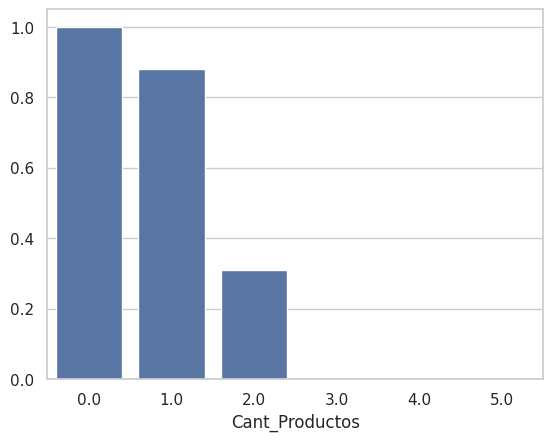

In [45]:
### TU CÓDIGO AQUÍ ##
tasa_fuga_productos = df_banco.groupby('Cant_Productos')['Fuga_Ultimo_Mes'].mean()
sns.barplot(x=tasa_fuga_productos.index, y=tasa_fuga_productos.values)

**6.2 Fuga e ingresos.** Calcula en `ingreso_por_fuga` el **ingreso mensual mediano** de los que se quedaron y de los que se fugaron, y construye un **boxplot** que compare las dos distribuciones.

> 💡 `sns.boxplot(data=df_banco, x='Fuga_Ultimo_Mes', y='Ingreso_Mensual')`

<Axes: xlabel='Fuga_Ultimo_Mes', ylabel='Ingreso_Mensual'>

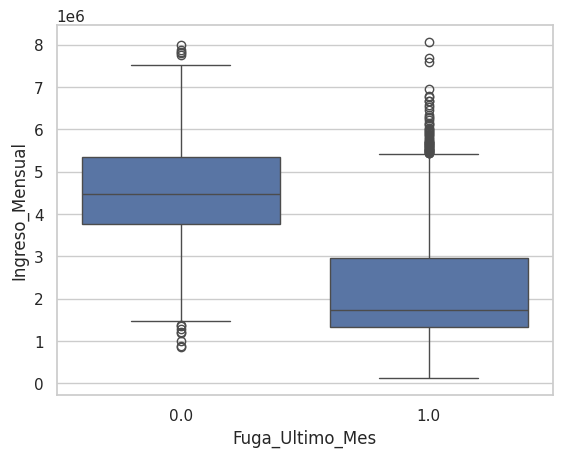

In [46]:
### TU CÓDIGO AQUÍ ###
ingreso_por_fuga = df_banco.groupby('Fuga_Ultimo_Mes')['Ingreso_Mensual'].median()
sns.boxplot(data=df_banco, x='Fuga_Ultimo_Mes', y='Ingreso_Mensual')

**6.3 La tabla ejecutiva.** La Junta no lee código: lee tablas. Construye en `tabla_ejecutiva` una tabla dinámica con la **tasa de fuga** cruzando `Ciudad` (en las filas) contra `Cant_Productos` (en las columnas).

> 💡 `df_banco.pivot_table(index=..., columns=..., values=..., aggfunc='mean')`

Imprímela redondeada a 3 decimales y léela con ojo de economista: ¿la fuga es un problema de *ciudad* o un problema de *relación comercial*? ¿Hay alguna ciudad que se salga del patrón?

In [65]:
### TU CÓDIGO AQUÍ ###
tabla_ejecutiva = df_banco.pivot_table(index='Ciudad', columns='Cant_Productos', values='Fuga_Ultimo_Mes', aggfunc='mean')
tabla_ejecutiva.columns = tabla_ejecutiva.columns.astype(int)
display(tabla_ejecutiva.round(3))

Cant_Productos,0,1,2,3,4,5
Ciudad,,,,,,
Barranquilla,1.00,0.77,0.23,0.00,0.00,0.00
Bogotá,1.00,0.90,0.30,0.00,0.00,0.00
Cali,1.00,0.89,0.39,0.00,0.00,0.00
Medellín,1.00,0.89,0.31,0.00,0.00,0.00


La `tabla_ejecutiva` muestra claramente que la fuga es, en mayor medida, un problema de relación comercial (cantidad de productos) y no tanto de ciudad. El patrón más fuerte es que la tasa de fuga disminuye drásticamente a medida que los clientes tienen más productos con el banco. Los clientes con 0 productos tienen una tasa de fuga del 100% en todas las ciudades, y esta tasa baja consistentemente a medida que el número de productos aumenta, llegando a 0% para 3 o más productos en todas las ciudades.

En cuanto a si alguna ciudad se sale del patrón, Cali muestra una tasa de fuga ligeramente más alta para clientes con 2 productos (0.39) en comparación con las otras ciudades (Barranquilla 0.23, Bogotá 0.30, Medellín 0.31). Por otro lado, Barranquilla tiene una tasa de fuga ligeramente más baja para clientes con 1 producto (0.77) y 2 productos (0.23) en comparación con las otras ciudades. Sin embargo, estas variaciones son menores en comparación con el impacto fundamental del número de productos en la fuga.

**6.4 La matriz de correlación.** Ahora midan qué tan asociada está cada variable con la fuga.

1. Calcula en `matriz_correlacion` la matriz de correlación de estas columnas, **en este orden**:

```python
columnas_numericas = ['Edad', 'Ingreso_Mensual', 'Saldo_Cuenta', 'Cant_Productos',
                      'Antiguedad_Anios', 'Ratio_Ahorro', 'Fuga_Ultimo_Mes']
```

2. Grafícala con un **heatmap**: `sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', center=0)`.
3. Guarda en `correlacion_con_fuga` la columna `Fuga_Ultimo_Mes` de esa matriz, **sin la diagonal** (quita la correlación de la fuga consigo misma, que siempre es 1) y **ordenada de menor a mayor** con `.sort_values()`.

> ⚠️ Fíjense en qué **no** entra a la matriz. `ID_Cliente` queda fuera porque es un identificador, no una variable económica: su correlación no significa nada. E `Ingreso_Anual` queda fuera porque es `Ingreso_Mensual × 12`, o sea la misma información: su correlación con el ingreso mensual es exactamente 1,0. Meter las dos es la misma trampa de multicolinealidad que van a evitar con `drop_first` en el Reto 8.

Al leer el resultado, comparen las variables de **comportamiento** (productos, saldo, ratio de ahorro) con las **demográficas** (edad, antigüedad). Y recuerden: la correlación dice dónde mirar, **no** dice qué causa qué.

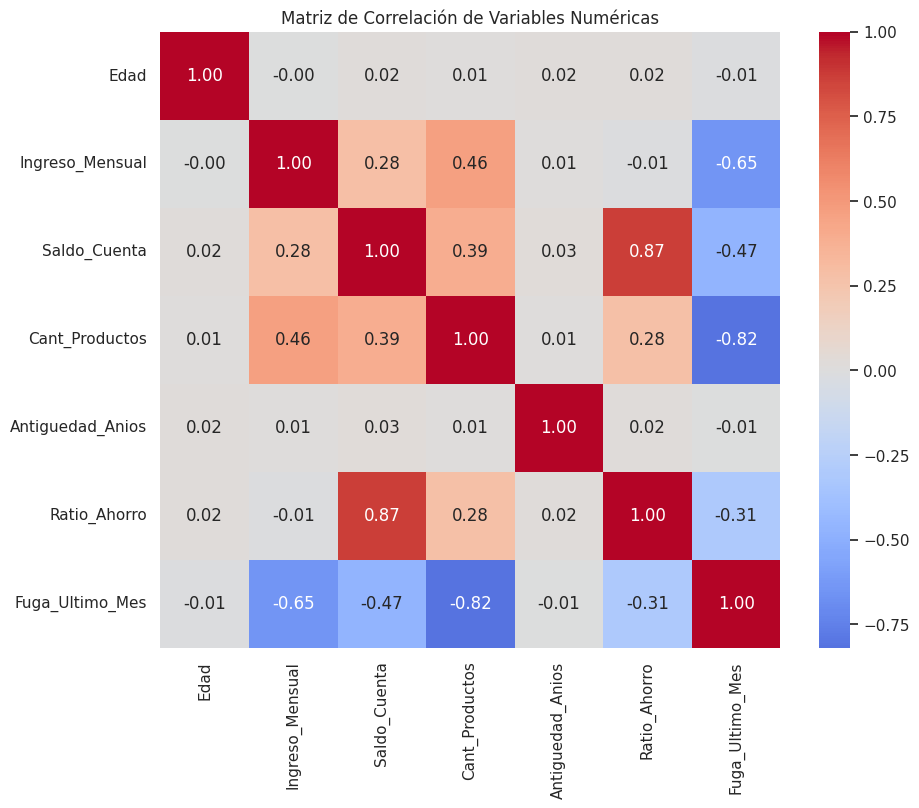

Correlación con Fuga_Ultimo_Mes (ordenada):
Cant_Productos     -0.82
Ingreso_Mensual    -0.65
Saldo_Cuenta       -0.47
Ratio_Ahorro       -0.31
Edad               -0.01
Antiguedad_Anios   -0.01
Name: Fuga_Ultimo_Mes, dtype: float64


In [49]:
columnas_numericas = ['Edad', 'Ingreso_Mensual', 'Saldo_Cuenta', 'Cant_Productos',
                      'Antiguedad_Anios', 'Ratio_Ahorro', 'Fuga_Ultimo_Mes']

matriz_correlacion = df_banco[columnas_numericas].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', center=0, fmt=".2f")
plt.title('Matriz de Correlación de Variables Numéricas')
plt.show()

correlacion_con_fuga = matriz_correlacion['Fuga_Ultimo_Mes'].drop('Fuga_Ultimo_Mes').sort_values()

print("Correlación con Fuga_Ultimo_Mes (ordenada):")
print(correlacion_con_fuga)

### Pitch Económico para la Junta Directiva

Estimados miembros de la Junta Directiva,

Nuestros análisis revelan que la fuga de clientes en el Banco Externado no es un problema aleatorio, sino que está fuertemente correlacionada con la profundidad de la relación comercial. La variable más predictiva de la fuga es la **cantidad de productos** que un cliente tiene con el banco, con una correlación negativa de -0.82. Esto indica que a mayor número de productos, menor es la probabilidad de fuga. Esta relación se explica por los **costos de cambio**: cada producto adicional incrementa el esfuerzo y la fricción que un cliente debe enfrentar para cambiar de proveedor financiero, incentivando la permanencia. Los clientes con 0 productos tienen una tasa de fuga del 100%, mientras que aquellos con 3 o más productos muestran una tasa de fuga del 0%.

Crucialmente, el banco está perdiendo a sus **clientes menos rentables**. Observamos que el **ingreso mensual mediano** de los clientes que se fugan es de $1.732.029,15, significativamente menor que el de los clientes que se quedan, cuyo ingreso mediano es de $4.476.980,86. Esto implica que, aunque preocupante, la fuga actual tiene un impacto menos severo en el Valor Presente Neto de la cartera, ya que los clientes de bajo ingreso son quienes mayoritariamente se están yendo. Los segmentos de ingreso 'Bajo' (hasta 2 millones) tienen una tasa de fuga del 97%, mientras que los segmentos 'Medio' (2-5 millones) y 'Alto' (más de 5 millones) tienen tasas de fuga del 24% y 12% respectivamente.

La **matriz de correlación** enfatiza que las variables de **comportamiento** (`Cant_Productos`: -0.82; `Ingreso_Mensual`: -0.65; `Saldo_Cuenta`: -0.47; `Ratio_Ahorro`: -0.31) son los principales impulsores de la fuga. En contraste, las variables **demográficas** como `Edad` y `Antiguedad_Anios` muestran una correlación casi nula (-0.01) con la fuga. Esto significa que el banco debe centrar sus estrategias de retención no en características estáticas del cliente, sino en fortalecer la relación comercial y la oferta de productos. La tasa de fuga por ciudad y número de productos (tabla ejecutiva) confirma esta tendencia: si bien hay ligeras variaciones entre ciudades (Cali presenta una fuga marginalmente superior en clientes con 2 productos, 0.39 vs. 0.23-0.31 en otras), el factor dominante en todas es la cantidad de productos.

En conclusión, la fuga es un problema de relación comercial más que demográfico o geográfico. Los clientes se van cuando tienen pocos lazos con el banco, y estos suelen ser los de menor ingreso. La clave está en la vinculación y la proposición de valor diferencial para retener a los clientes más valiosos y profundizar la relación con todos ellos.

---
# 🏆 **Reto 7: El diagnóstico para la Junta Directiva**

Este reto lo lee y lo califica la profesora.

Ya tienen toda la evidencia: la tasa de fuga por segmento, por cantidad de productos y por ciudad, el ratio de ahorro y la matriz de correlación. Ahora hay que convertir eso en un argumento.

**7.1 El pitch económico.**

Guarda en una variable de texto llamada `pitch_economico` (mínimo 500 caracteres) el diagnóstico que le presentarían a la Junta Directiva.

**No describan las gráficas** ("la barra azul es más alta"). Expliquen el **mecanismo económico** detrás:

- ¿Por qué tener más productos reduce la fuga? *(piensen en costos de cambio y en relación de largo plazo con el banco)*
- El banco, ¿está perdiendo a sus clientes más rentables o a los menos rentables? ¿Qué implica eso para el valor presente neto de la cartera?
- ¿Qué les dice la matriz de correlación sobre el tipo de variable que anticipa la fuga: las de comportamiento o las demográficas? ¿Qué consecuencia tiene eso para dónde debe mirar el banco?
- Usen las cifras que ya calcularon (`fuga_por_segmento`, `ratio_por_fuga`, `tasa_fuga_productos`, `tabla_ejecutiva`, `correlacion_con_fuga`) como evidencia: un pitch con números vale más que uno con adjetivos.

**7.2 Recomendaciones.** Guarda en `recomendaciones` una **lista de al menos 3 textos**, cada uno con una medida concreta que le recomiendan a la Junta para reducir la fuga, **basada en los datos** (no en intuiciones generales). Cada recomendación debe tener al menos 60 caracteres.

```python
recomendaciones = [
    "Primera medida...",
    "Segunda medida...",
    "Tercera medida...",
]
```

In [50]:
recomendaciones = [
    "1. Implementar programas de profundización de la relación con el cliente, incentivando la adquisición de productos adicionales para aumentar los costos de cambio y fortalecer la lealtad.",
    "2. Desarrollar estrategias de retención diferenciadas, priorizando a clientes de alto valor (mayores ingresos y saldos) con ofertas personalizadas, ya que son los menos propensos a la fuga actual.",
    "3. Evaluar y ajustar la oferta de productos y servicios para los segmentos de 'Ingreso Bajo' y 'Medio', que presentan las tasas de fuga más altas, para aumentar su vinculación y rentabilidad."
]

for i, r in enumerate(recomendaciones, 1):
    print(f"{i}. {r}\n")

1. 1. Implementar programas de profundización de la relación con el cliente, incentivando la adquisición de productos adicionales para aumentar los costos de cambio y fortalecer la lealtad.

2. 2. Desarrollar estrategias de retención diferenciadas, priorizando a clientes de alto valor (mayores ingresos y saldos) con ofertas personalizadas, ya que son los menos propensos a la fuga actual.

3. 3. Evaluar y ajustar la oferta de productos y servicios para los segmentos de 'Ingreso Bajo' y 'Medio', que presentan las tasas de fuga más altas, para aumentar su vinculación y rentabilidad.



---
# 🧩 **Reto 8: Preparación para Machine Learning**

Dejen la base lista para entrenar después un modelo de predicción de fuga.

**8.1 Variables dummy.** Las máquinas no leen texto.

1. Crea `df_ml` como una copia de `df_banco` **sin** las columnas `Fecha_Ingreso` ni `Segmento_Ingreso` (la primera ya está representada por `Antiguedad_Anios`, y la segunda por `Ingreso_Mensual`).
2. Aplica *One-Hot Encoding* a `Genero` y `Ciudad`. Usa `drop_first=True` para **evitar la multicolinealidad exacta** (la trampa de la variable dummy): con *k* categorías bastan *k−1* columnas, porque la que falta queda representada cuando todas las demás valen 0.

> 💡 `pd.get_dummies(df, columns=['Genero', 'Ciudad'], drop_first=True)`

In [55]:
### TU CÓDIGO AQUÍ ###
df_ml = df_banco.drop(columns=['Fecha_Ingreso', 'Segmento_Ingreso']).copy()
df_ml = pd.get_dummies(df_ml, columns=['Genero', 'Ciudad'], drop_first=True)

**8.2 Escalamiento.** `Ingreso_Mensual` está en millones y `Saldo_Cuenta` en miles: un algoritmo que mide distancias le daría un peso artificialmente mayor a la primera. Escala **ambas columnas** dentro de `df_ml`.

Pueden usar `StandardScaler` (media 0, desviación 1) o `MinMaxScaler` (entre 0 y 1): la verificación acepta cualquiera de los dos.

> 💡 `from sklearn.preprocessing import StandardScaler` → `scaler.fit_transform(df_ml[cols])`

In [56]:
from sklearn.preprocessing import StandardScaler

columns_to_scale = ['Ingreso_Mensual', 'Saldo_Cuenta']

scaler = StandardScaler()
df_ml[columns_to_scale] = scaler.fit_transform(df_ml[columns_to_scale])

---
# 🏆 Cómo ganar la Datatón

1. Ejecuten la celda de verificación de abajo y asegúrense de llegar al **100 %**.
2. Suban el notebook a su cuenta de GitHub y envíen el link en el siguiente formulario: https://forms.cloud.microsoft/r/Mx8ukUdwvn

Gana el equipo que **(i)** llegue al 100 % en la verificación automática, **(ii)** tenga el mejor pitch económico y las mejores recomendaciones —eso lo evalúa la profesora— y **(iii)** entregue más rápido.

**Premio:** + 5 décimas en la nota más baja que tenga entre el segundo parcial, talleres del segundo corte o quices del segundo corte.

¡El tiempo corre! 🕐

---
## 🤖 Verificación automática

Ejecuta esta celda cuando quieras: te dice en qué porcentaje vas y **en cuál punto exacto** está el error.

**No modifiques esta celda.**

In [66]:
# =============================================================================
#  VERIFICACIÓN AUTOMÁTICA DE LA DATATÓN  ·  no modifiquen esta celda
# =============================================================================
import hashlib

import numpy as _np
import pandas as _pd

_SAL = b"extdo-dataton-2026-II"
_ITERACIONES = 60_000


def _canon(x):
    """Convierte cualquier resultado (incluidos objetos de NumPy y pandas) en un
    texto único y estable, para poder compararlo sin revelar la respuesta."""
    if x is None:
        return "N"
    if isinstance(x, (bool, _np.bool_)):
        return "B" + str(bool(x))
    if isinstance(x, _np.generic):            # np.float64, np.int64, np.str_...
        return _canon(x.item())
    if isinstance(x, (int, float)):           # int y float se tratan igual
        v = float(x)
        if v != v or v in (float("inf"), float("-inf")):
            return "X" + str(v)
        return "#" + ("%.6g" % v)
    if isinstance(x, str):
        return "S" + x.strip()
    if isinstance(x, _pd.DataFrame):
        return ("DF[" + _canon(list(x.columns)) + ";" + _canon(list(x.shape))
                + ";" + _canon(x.to_dict()) + "]")
    if isinstance(x, _pd.Series):
        return "SE[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (_pd.Index, _pd.Categorical)):
        return _canon(list(x))
    if isinstance(x, dict):
        return "D[" + ",".join(sorted(_canon(k) + "=" + _canon(v) for k, v in x.items())) + "]"
    if isinstance(x, (set, frozenset)):
        return "C[" + ",".join(sorted(_canon(i) for i in x)) + "]"
    if isinstance(x, (list, tuple)):
        return "L[" + ",".join(_canon(i) for i in x) + "]"
    return "O" + repr(x)


def _huella(clave, valor):
    """Huella lenta a propósito (~60.000 iteraciones): verificar el notebook
    cuesta un par de segundos, pero adivinar la respuesta probando candidatos
    se vuelve inviable."""
    mensaje = (str(clave) + "|" + _canon(valor)).encode("utf-8")
    return hashlib.pbkdf2_hmac("sha256", mensaje, _SAL, _ITERACIONES).hex()[:16]


def _verificar_escalado(df, columnas):
    """Acepta StandardScaler (media 0, desviación 1) o MinMaxScaler (entre 0 y 1)."""
    for col in columnas:
        s = _pd.to_numeric(df[col], errors="coerce").astype(float)
        estandarizada = abs(s.mean()) < 0.01 and abs(s.std() - 1) < 0.05
        normalizada = abs(s.min()) < 0.01 and abs(s.max() - 1) < 0.01
        if not (estandarizada or normalizada):
            return "sin escalar"
    return "escalado correcto"


_RETOS = {
    "1": "Reto 1 · Auditoría e integración",
    "2": "Reto 2 · Limpieza quirúrgica",
    "3": "Reto 3 · Outliers con regla del IQR",
    "4": "Reto 4 · Transformación de variables",
    "5": "Reto 5 · Segmentación de clientes",
    "6": "Reto 6 · Análisis exploratorio (EDA)",
    "7": "Reto 7 · El diagnóstico para la Junta",
    "8": "Reto 8 · Preparación para Machine Learning",
}

#  (punto, título, huella esperada, cómo se obtiene el resultado, pista si falla)
_PRUEBAS = [
    ("1.1", "Duplicados contados y eliminados", "adb42464f8941814",
     lambda: [n_duplicados, df_clientes.shape, round(float(df_clientes['Ingreso_Mensual'].sum()), 2)],
     "n_duplicados debe contarse ANTES de eliminar, y df_clientes debe quedar sin filas repetidas."),
    ("1.2", "Llave estandarizada y tablas unidas", "07da75d9fb8cdb5a",
     lambda: [dim_banco, sorted(str(c) for c in df_banco.columns), round(float(df_banco['Saldo_Cuenta'].sum()), 2)],
     "El resultado debe conservar TODAS las filas de df_clientes, incluidos los clientes sin transacciones. Revisa también que la llave ID_Cliente haya quedado numérica en las dos tablas."),
    ("2.1", "Género estandarizado en 3 categorías", "7bf63f3266fd072b",
     lambda: [generos_finales, df_banco.groupby('Genero')['ID_Cliente'].sum()],
     "Deben quedar exactamente 'Femenino', 'Masculino' y 'Otro'. Revisa que 'm' y 'M' hayan caído en la misma categoría."),
    ("2.2", "Ciudad estandarizada en 4 categorías", "3b322fd1e16bf5a2",
     lambda: [ciudades_finales, df_banco.groupby('Ciudad')['ID_Cliente'].sum()],
     "Deben quedar exactamente 'Barranquilla', 'Bogotá', 'Cali' y 'Medellín', con tilde. Ojo con los espacios sobrantes: .str.strip() va primero."),
    ("2.3", "Nulos imputados con el criterio pedido", "1333bd0e126a2ed5",
     lambda: [nulos_restantes, round(float(mediana_edad), 2), round(float(mediana_ingreso), 2), round(float(df_banco['Saldo_Cuenta'].sum()), 2), round(float(df_banco['Fuga_Ultimo_Mes'].sum()), 2)],
     "Mediana para Edad e Ingreso_Mensual, 0 para Saldo_Cuenta y Cant_Productos, 1 para Fuga_Ultimo_Mes. Las medianas se calculan ANTES de imputar."),
    ("2.4", "Outlier de edad corregido", "04902517c8d52566",
     lambda: [round(float(edad_maxima), 2), round(float(df_banco['Edad'].mean()), 4), round(float(df_banco['Edad'].sum()), 2)],
     "Reemplaza por mediana_edad la edad de quienes superan los 100 años, DESPUÉS de haber imputado los nulos."),
    ("3.1", "Límites del IQR y conteo de atípicos", "fae61995e532b85f",
     lambda: [n_outliers_saldo, round(float(q1_saldo), 4), round(float(q3_saldo), 4), round(float(iqr_saldo), 4), round(float(limite_inferior_saldo), 4), round(float(limite_superior_saldo), 4)],
     "IQR = Q3 - Q1, y los límites son Q1 - 1.5*IQR y Q3 + 1.5*IQR. Cuenta los que quedan por fuera del intervalo, por debajo O por encima."),
    ("4.1", "Columna Ingreso_Anual", "465d2eb5c5f96b07",
     lambda: [round(float(df_banco['Ingreso_Anual'].mean()), 4), round(float(df_banco['Ingreso_Anual'].sum()) / 1e6, 2)],
     "Ingreso_Anual = Ingreso_Mensual * 12. Si falla y el reto 2 está en verde, revisa que no hayas escalado el ingreso antes de tiempo."),
    ("4.2", "Antigüedad en años a la fecha de corte", "344db6c0f6ffe2bc",
     lambda: [round(float(df_banco['Antiguedad_Anios'].mean()), 4), round(float(df_banco['Antiguedad_Anios'].max()), 2), round(float(df_banco['Antiguedad_Anios'].min()), 2)],
     "Usa FECHA_CORTE (1 de enero de 2026), divide los días entre 365.25 y redondea la columna a 2 decimales con .round(2)."),
    ("4.3", "Ratio de ahorro por grupo de fuga", "a2bffd5ff20e15ec",
     lambda: [ratio_por_fuga, round(float(df_banco['Ratio_Ahorro'].mean()), 6)],
     "Ratio_Ahorro = Saldo_Cuenta / Ingreso_Mensual, y el promedio se agrupa con groupby sobre Fuga_Ultimo_Mes."),
    ("4.4", "Resumen de saldo por género y fuga", "c011d9c863eff393",
     lambda: [resumen_saldo],
     "Agrupa por las dos variables a la vez: groupby(['Genero', 'Fuga_Ultimo_Mes'])['Saldo_Cuenta'].mean()."),
    ("5.1", "Segmentos de ingreso con pd.cut", "330adde46c7cb20a",
     lambda: [conteo_segmentos, round(float(df_banco['Ingreso_Mensual'].sum()), 2)],
     "Usa los cortes [0, 2_000_000, 5_000_000, np.inf] con las etiquetas 'Bajo', 'Medio' y 'Alto', en ese orden."),
    ("5.2", "Tasa de fuga por segmento", "a6af3255b1807a2d",
     lambda: [fuga_por_segmento],
     "Agrupa por Segmento_Ingreso y saca el promedio de Fuga_Ultimo_Mes: al ser 0/1, el promedio es la proporción de fuga."),
    ("6.1", "Tasa de fuga por cantidad de productos", "b8051ef49d133ac7",
     lambda: [tasa_fuga_productos],
     "groupby sobre Cant_Productos y .mean() de Fuga_Ultimo_Mes. Si el reto 2 está bien, debe aparecer también el grupo de 0 productos."),
    ("6.2", "Ingreso mediano por grupo de fuga", "512a2df38d08857e",
     lambda: [ingreso_por_fuga],
     "Es la MEDIANA (no la media) del Ingreso_Mensual, agrupada por Fuga_Ultimo_Mes."),
    ("6.3", "Tabla ejecutiva de fuga por ciudad y productos", "3fe7deacfe36028e",
     lambda: [tabla_ejecutiva],
     "Usa pivot_table con Ciudad en index, Cant_Productos en columns, Fuga_Ultimo_Mes en values y aggfunc='mean'. La tabla debe quedar de 4 filas por 6 columnas."),
    ("6.4", "Matriz de correlación con la fuga", "6c3f5fd51b308418",
     lambda: [correlacion_con_fuga, round(float(matriz_correlacion.values.sum()), 6)],
     "Usa exactamente las 7 columnas de la lista, en ese orden. A correlacion_con_fuga hay que quitarle la diagonal (la fuga consigo misma) y ordenarla con .sort_values()."),
    ("8.1", "Variables dummy sin multicolinealidad", "27728a0a274d3457",
     lambda: [sorted(str(c) for c in df_ml.columns), int(df_ml['Genero_Masculino'].sum()), int(df_ml['Genero_Otro'].sum()), int(df_ml['Ciudad_Cali'].sum())],
     "Elimina Fecha_Ingreso y Segmento_Ingreso, y aplica get_dummies a Genero y Ciudad con drop_first=True (deben quedar 2 dummies de género y 3 de ciudad)."),
    ("8.2", "Columnas escaladas", "a0ddf51a33e585f0",
     lambda: _verificar_escalado(df_ml, ['Ingreso_Mensual', 'Saldo_Cuenta']),
     "Escala AMBAS columnas dentro de df_ml con StandardScaler o MinMaxScaler. Recuerda reasignar el resultado: df_ml[cols] = scaler.fit_transform(df_ml[cols])."),
]

#  Puntos de análisis escrito: los califica la profesora, no suman al porcentaje
_REVISION = [
    ("3.2", "Decisión argumentada sobre los outliers de saldo", lambda: decision_outliers, "texto", 150),
    ("7.1", "Pitch económico para la Junta Directiva", lambda: pitch_economico, "texto", 500),
    ("7.2", "Recomendaciones basadas en los datos", lambda: recomendaciones, "lista", 3),
]


def _estado_de(prueba):
    clave, _titulo, esperado, obtener, _pista = prueba
    try:
        return "ok" if _huella(clave, obtener()) == esperado else "mal"
    except NameError:
        return "falta"
    except Exception:
        return "error"


def _estado_revision(item):
    _clave, _titulo, obtener, tipo, minimo = item
    try:
        valor = obtener()
    except NameError:
        return "falta", "todavía no la has creado"
    except Exception:
        return "error", "no se pudo leer"

    if tipo == "texto":
        if not isinstance(valor, str):
            return "mal", "debe ser un texto entre comillas"
        texto = valor.strip()
        if "TU TEXTO AQUÍ" in texto or "###" in texto:
            return "falta", "sigue con el texto de ejemplo"
        if len(texto) < minimo:
            return "mal", "van %d caracteres de %d" % (len(texto), minimo)
        return "ok", "%d caracteres" % len(texto)

    if not isinstance(valor, (list, tuple)):
        return "mal", "debe ser una lista de textos"
    utiles = [t for t in valor
              if isinstance(t, str) and len(t.strip()) >= 60 and "###" not in t]
    if len(utiles) < minimo:
        return "mal", "van %d recomendaciones válidas de %d (mínimo 60 caracteres cada una)" % (len(utiles), minimo)
    return "ok", "%d recomendaciones" % len(utiles)


_ICONO = {"ok": "\u2705", "mal": "\u274c", "falta": "\u23f3", "error": "\u26a0\ufe0f"}


def verificar_dataton():
    resultados = [(p, _estado_de(p)) for p in _PRUEBAS]

    print("=" * 66)
    print("  VERIFICACIÓN AUTOMÁTICA · DATATÓN BANCO EXTERNADO")
    print("=" * 66)

    reto_actual = None
    for (clave, titulo, _esp, _obt, _pista), estado in resultados:
        reto = clave.split(".")[0]
        if reto != reto_actual:
            reto_actual = reto
            print("\n  " + _RETOS[reto])
        print("    %s  %-4s %s" % (_ICONO[estado], clave, titulo))

    correctos = sum(1 for _p, e in resultados if e == "ok")
    total = len(resultados)
    porcentaje = round(correctos * 100 / total)
    llenas = round(porcentaje / 5)
    barra = "\u2588" * llenas + "\u2591" * (20 - llenas)

    print("\n" + "-" * 66)
    print("  AVANCE: %d de %d puntos automáticos   ->   %d %%" % (correctos, total, porcentaje))
    print("  [%s]" % barra)
    print("-" * 66)

    pendientes = [(c, t, e, pi) for (c, t, _e2, _o, pi), e in resultados if e != "ok"]
    if not pendientes:
        print("  🎉 ¡Base impecable! El informe para la Junta está completo.")
    else:
        print("  Qué falta por revisar (los %d primeros):\n" % min(len(pendientes), 5))
        for clave, titulo, estado, pista in pendientes[:5]:
            if estado == "falta":
                print("   ⏳ %s  %s" % (clave, titulo))
                print("      Aún no existe alguna de las variables que pide este punto.")
            elif estado == "error":
                print("   ⚠️  %s  %s" % (clave, titulo))
                print("      La variable existe pero algo falla al calcularla (¿falta una columna?).")
            else:
                print("   ❌ %s  %s" % (clave, titulo))
            print("      Pista: %s\n" % pista)
        if len(pendientes) > 5:
            print("   ... y %d punto(s) más. Arregla estos primero: los retos son"
                  " acumulativos y unos arrastran a otros.\n" % (len(pendientes) - 5))

    print("-" * 66)
    print("  📝 REVISIÓN DE LA PROFESORA (no suma al porcentaje automático)")
    print("     Estos son los puntos que deciden quién gana la Datatón.\n")
    reto_actual = None
    for item in _REVISION:
        reto = item[0].split(".")[0]
        if reto != reto_actual:
            reto_actual = reto
            print("  " + _RETOS[reto])
        estado, detalle = _estado_revision(item)
        print("    %s  %-4s %s" % (_ICONO[estado], item[0], item[1]))
        print("          %s" % detalle)
    print("=" * 66)


verificar_dataton()


  VERIFICACIÓN AUTOMÁTICA · DATATÓN BANCO EXTERNADO

  Reto 1 · Auditoría e integración
    ✅  1.1  Duplicados contados y eliminados
    ✅  1.2  Llave estandarizada y tablas unidas

  Reto 2 · Limpieza quirúrgica
    ✅  2.1  Género estandarizado en 3 categorías
    ✅  2.2  Ciudad estandarizada en 4 categorías
    ✅  2.3  Nulos imputados con el criterio pedido
    ✅  2.4  Outlier de edad corregido

  Reto 3 · Outliers con regla del IQR
    ✅  3.1  Límites del IQR y conteo de atípicos

  Reto 4 · Transformación de variables
    ✅  4.1  Columna Ingreso_Anual
    ✅  4.2  Antigüedad en años a la fecha de corte
    ✅  4.3  Ratio de ahorro por grupo de fuga
    ✅  4.4  Resumen de saldo por género y fuga

  Reto 5 · Segmentación de clientes
    ✅  5.1  Segmentos de ingreso con pd.cut
    ✅  5.2  Tasa de fuga por segmento

  Reto 6 · Análisis exploratorio (EDA)
    ✅  6.1  Tasa de fuga por cantidad de productos
    ✅  6.2  Ingreso mediano por grupo de fuga
    ✅  6.3  Tabla ejecutiva de fuga po